<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Visualization**


Estimated time needed: **45** minutes


In this lab, you will focus on data visualization. The dataset will be provided through an RDBMS, and you will need to use SQL queries to extract the required data.


## Objectives


After completing this lab, you will be able to:


-   Visualize the distribution of data.

-   Visualize the relationship between two features.

-   Visualize composition and comparison of data.




## Demo: How to work with database


Download the database file.


In [1]:
# The original `!wget` magic command only runs in Jupyter/Linux environments.
# It is kept below as a comment. Use urllib instead so it works in plain VS Code.
# !wget https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
import os
import urllib.request
import urllib.error

csv_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
csv_file = 'survey-data.csv'
if not (os.path.exists(csv_file) and os.path.getsize(csv_file) > 0):
    print('Downloading survey-data.csv ...')
    urllib.request.urlretrieve(csv_url, csv_file)
print('CSV ready at:', os.path.abspath(csv_file))

CSV ready at: c:\Users\Jerome\github-jtgreta\ibm-data-analyst\09-ibm-data-analyst-capstone-project\survey-data.csv


**Install and Import Necessary Python Libraries**

Ensure that you have the required libraries installed to work with SQLite and Pandas:


In [2]:
# The original `!pip install` magic commands only run in Jupyter environments.
# They are kept below as comments. Use subprocess instead so the packages are
# installed with the same Python interpreter that is selected in VS Code.
# !pip install pandas
# !pip install matplotlib
import importlib.util
import subprocess
import sys

def install(package, import_name=None):
    """Quietly pip-install a package if it is not already available."""
    import_name = import_name or package
    try:
        spec = importlib.util.find_spec(import_name)
    except (ImportError, ModuleNotFoundError, ValueError):
        spec = None
    if spec is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package])

install('pandas', 'pandas')
install('matplotlib', 'matplotlib')

import pandas as pd
import matplotlib.pyplot as plt

**Read the CSV File into a Pandas DataFrame**

Load the Stack Overflow survey data into a Pandas DataFrame:


In [3]:
# Read the CSV file
# (cached locally so the notebook still runs when the network is down)
import os
import urllib.request
import urllib.error

data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
local_file = 'survey-data.csv'

def load_dataset(url, local_path, retries=3):
    if os.path.exists(local_path) and os.path.getsize(local_path) > 0:
        try:
            return pd.read_csv(local_path)
        except Exception:
            pass
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            urllib.request.urlretrieve(url, local_path)
            return pd.read_csv(local_path)
        except (urllib.error.URLError, OSError) as e:
            last_err = e
            print(f"Download attempt {attempt}/{retries} failed: {e}")
    raise RuntimeError(
        "Could not download the dataset.\n"
        f"URL: {url}\nLast error: {last_err}\n"
        "Check your internet connection / VPN / proxy, or place a copy of the "
        f"CSV named '{local_path}' next to this notebook."
    )

df = load_dataset(data_url, local_file)

# Display the first few rows of the data
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


**Create a SQLite Database and Insert the Data**

Now, let's create a new SQLite database (`survey-data.sqlite`) and insert the data from the DataFrame into a table using the sqlite3 library:


In [4]:
import sqlite3

# Create a connection to the SQLite database
conn = sqlite3.connect('survey-data.sqlite')

# Write the dataframe to the SQLite database
df.to_sql('main', conn, if_exists='replace', index=False)


# Close the connection
conn.close()


**Verify the Data in the SQLite Database**
Verify that the data has been correctly inserted into the SQLite database by running a simple query:


In [5]:
# Reconnect to the SQLite database
conn = sqlite3.connect('survey-data.sqlite')

# Run a simple query to check the data
QUERY = "SELECT * FROM main LIMIT 5"
df_check = pd.read_sql_query(QUERY, conn)

# Display the results
print(df_check)


   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

## Demo: Running an SQL Query


Count the number of rows in the table named 'main'


In [6]:
QUERY = """
SELECT COUNT(*) 
FROM main
"""
# df = pd.read_sql_query(QUERY, conn)   # original (overwrote df, breaking later cells)
count_df = pd.read_sql_query(QUERY, conn)
count_df.head()


,COUNT(*)
0,65437


## Demo: Listing All Tables


To view the names of all tables in the database:


In [7]:
QUERY = """
SELECT name as Table_Name FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)


,Table_Name
0,main


## Demo: Running a Group By Query
    
For example, you can group data by a specific column, like Age, to get the count of respondents in each age group:


In [8]:
QUERY = """
SELECT Age, COUNT(*) as count
FROM main
GROUP BY Age
ORDER BY Age
"""
pd.read_sql_query(QUERY, conn)


,Age,count
0,18-24 years old,14098
1,25-34 years old,23911
2,35-44 years old,14942
3,45-54 years old,6249
4,55-64 years old,2575
5,65 years or older,772
6,Prefer not to say,322
7,Under 18 years old,2568


## Demo: Describing a table

Use this query to get the schema of a specific table, main in this case:


In [9]:
table_name = 'main'

QUERY = """
SELECT sql FROM sqlite_master 
WHERE name= '{}'
""".format(table_name)

# df = pd.read_sql_query(QUERY, conn)   # original (overwrote df, breaking later cells)
schema_df = pd.read_sql_query(QUERY, conn)
print(schema_df.iat[0, 0])


CREATE TABLE "main" (
"ResponseId" INTEGER,
  "MainBranch" TEXT,
  "Age" TEXT,
  "Employment" TEXT,
  "RemoteWork" TEXT,
  "Check" TEXT,
  "CodingActivities" TEXT,
  "EdLevel" TEXT,
  "LearnCode" TEXT,
  "LearnCodeOnline" TEXT,
  "TechDoc" TEXT,
  "YearsCode" TEXT,
  "YearsCodePro" TEXT,
  "DevType" TEXT,
  "OrgSize" TEXT,
  "PurchaseInfluence" TEXT,
  "BuyNewTool" TEXT,
  "BuildvsBuy" TEXT,
  "TechEndorse" TEXT,
  "Country" TEXT,
  "Currency" TEXT,
  "CompTotal" REAL,
  "LanguageHaveWorkedWith" TEXT,
  "LanguageWantToWorkWith" TEXT,
  "LanguageAdmired" TEXT,
  "DatabaseHaveWorkedWith" TEXT,
  "DatabaseWantToWorkWith" TEXT,
  "DatabaseAdmired" TEXT,
  "PlatformHaveWorkedWith" TEXT,
  "PlatformWantToWorkWith" TEXT,
  "PlatformAdmired" TEXT,
  "WebframeHaveWorkedWith" TEXT,
  "WebframeWantToWorkWith" TEXT,
  "WebframeAdmired" TEXT,
  "EmbeddedHaveWorkedWith" TEXT,
  "EmbeddedWantToWorkWith" TEXT,
  "EmbeddedAdmired" TEXT,
  "MiscTechHaveWorkedWith" TEXT,
  "MiscTechWantToWorkWith" TEXT,


## Hands-on Lab


### Visualizing the Distribution of Data

**Histograms**

Plot a histogram of CompTotal (Total Compensation).


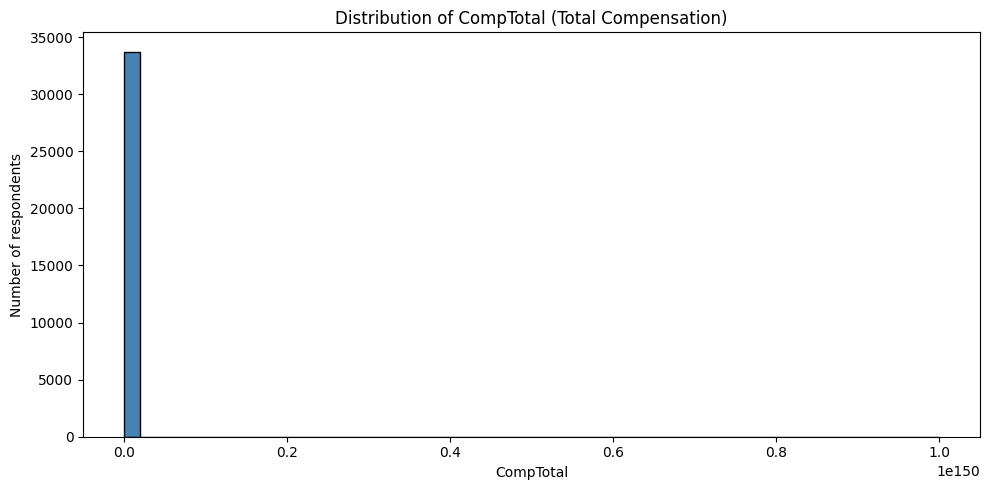

In [10]:
## Write your code here
# Histogram of CompTotal (Total Compensation)
plt.figure(figsize=(10, 5))
df['CompTotal'].dropna().plot(kind='hist', bins=50, color='steelblue', edgecolor='black')
plt.title('Distribution of CompTotal (Total Compensation)')
plt.xlabel('CompTotal')
plt.ylabel('Number of respondents')
plt.tight_layout()
plt.show()

**Box Plots**

Plot a box plot of Age.


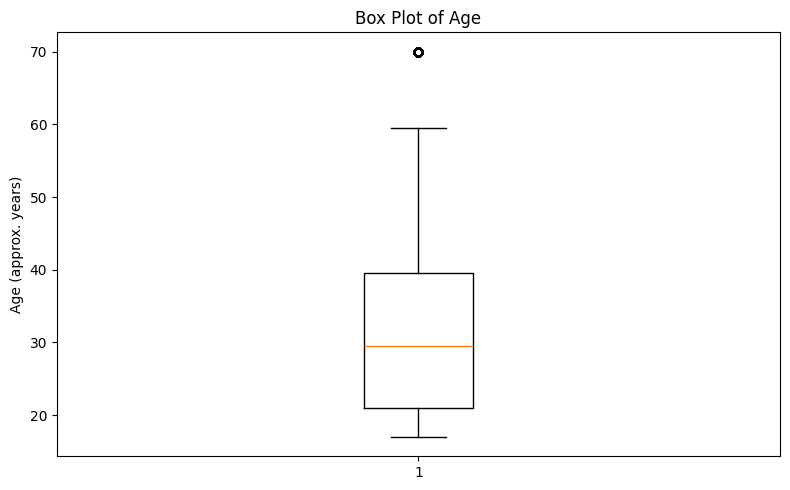

In [11]:
## Write your code here
# Box plot of Age (mapped to numeric midpoints of each age range)
age_mid = {
    'Under 18 years old': 17,
    '18-24 years old': 21,
    '25-34 years old': 29.5,
    '35-44 years old': 39.5,
    '45-54 years old': 49.5,
    '55-64 years old': 59.5,
    '65 years or older': 70,
}
age_numeric = df['Age'].map(age_mid)
plt.figure(figsize=(8, 5))
plt.boxplot(age_numeric.dropna(), vert=True)
plt.title('Box Plot of Age')
plt.ylabel('Age (approx. years)')
plt.tight_layout()
plt.show()

### Visualizing Relationships in Data

**Scatter Plots**

Create a scatter plot of Age and WorkExp.


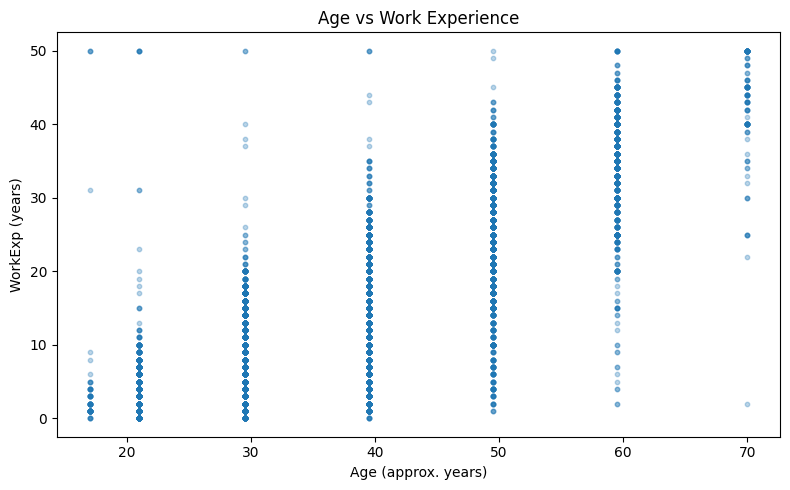

In [12]:
## Write your code here
# Scatter plot of Age (numeric) vs WorkExp
age_mid = {
    'Under 18 years old': 17,
    '18-24 years old': 21,
    '25-34 years old': 29.5,
    '35-44 years old': 39.5,
    '45-54 years old': 49.5,
    '55-64 years old': 59.5,
    '65 years or older': 70,
}
plot_df = df[['Age', 'WorkExp']].copy()
plot_df['AgeNum'] = plot_df['Age'].map(age_mid)
plot_df = plot_df.dropna(subset=['AgeNum', 'WorkExp'])
plt.figure(figsize=(8, 5))
plt.scatter(plot_df['AgeNum'], plot_df['WorkExp'], alpha=0.3, s=10)
plt.title('Age vs Work Experience')
plt.xlabel('Age (approx. years)')
plt.ylabel('WorkExp (years)')
plt.tight_layout()
plt.show()

**Bubble Plots**

Create a bubble plot of `TimeSearching` and `Frustration` using the Age column as the bubble size.


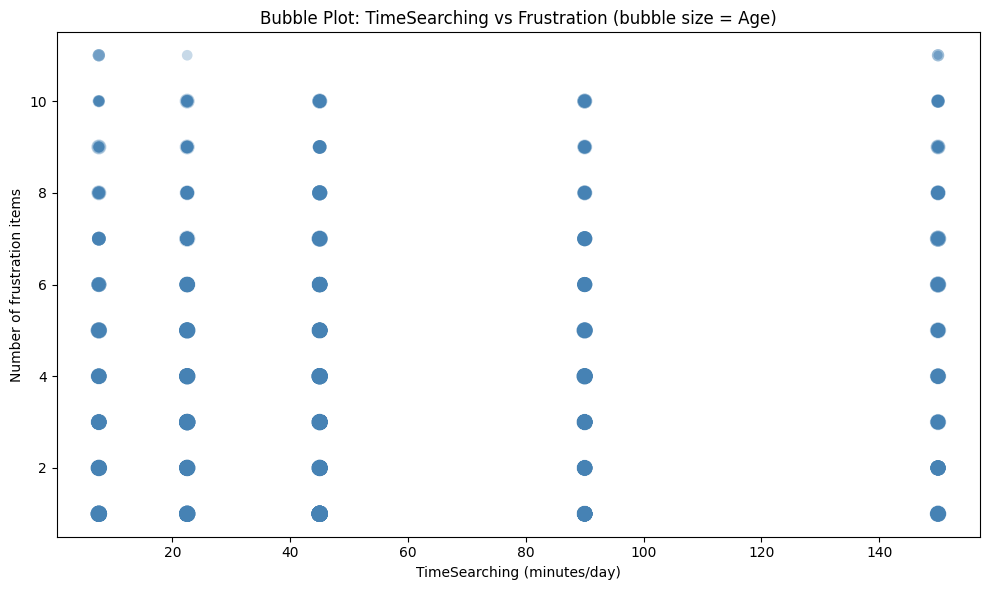

In [13]:
## Write your code here
# Bubble plot: TimeSearching (x) vs number of frustration items (y),
# with Age (numeric) as the bubble size
time_map = {
    'Less than 15 minutes a day': 7.5,
    '15-30 minutes a day': 22.5,
    '30-60 minutes a day': 45,
    '60-120 minutes a day': 90,
    'Over 120 minutes a day': 150,
}
age_mid = {
    'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70,
}
bubble_df = df[['TimeSearching', 'Frustration', 'Age']].dropna(subset=['TimeSearching']).copy()
bubble_df['TimeMin'] = bubble_df['TimeSearching'].map(time_map)
bubble_df['FrustrationCount'] = bubble_df['Frustration'].fillna('None of these').str.count(';') + 1
bubble_df['AgeNum'] = bubble_df['Age'].map(age_mid)
bubble_df = bubble_df.dropna(subset=['TimeMin', 'AgeNum'])

plt.figure(figsize=(10, 6))
plt.scatter(bubble_df['TimeMin'], bubble_df['FrustrationCount'],
            s=bubble_df['AgeNum'] * 2, alpha=0.3, c='steelblue', edgecolors='none')
plt.title('Bubble Plot: TimeSearching vs Frustration (bubble size = Age)')
plt.xlabel('TimeSearching (minutes/day)')
plt.ylabel('Number of frustration items')
plt.tight_layout()
plt.show()

### Visualizing Composition of Data

**Pie Charts**

Create a pie chart of the top 5 databases(`DatabaseWantToWorkWith`) that respondents wish to learn next year.


DatabaseWantToWorkWith
PostgreSQL    24005
SQLite        13489
MySQL         12269
MongoDB       10982
Redis         10847
Name: count, dtype: int64


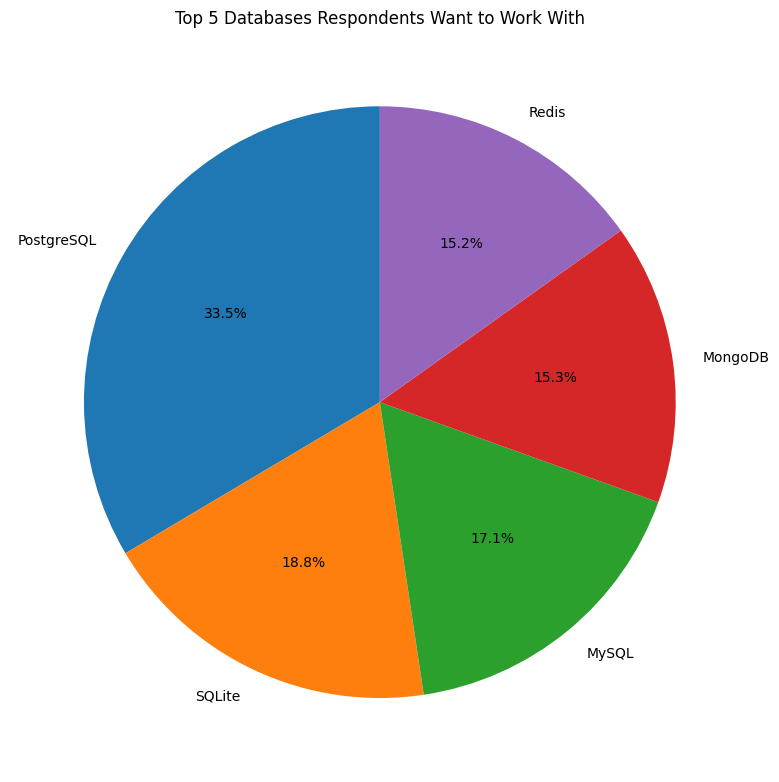

In [14]:
## Write your code here
# Pie chart of the top 5 databases respondents wish to learn next year
db_counts = df['DatabaseWantToWorkWith'].dropna().str.split(';').explode().value_counts().head(5)
print(db_counts)
plt.figure(figsize=(8, 8))
db_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Top 5 Databases Respondents Want to Work With')
plt.ylabel('')
plt.tight_layout()
plt.show()

**Stacked Charts** 

Create a stacked bar chart of median `TimeSearching` and `TimeAnswering` for the age group 30 to 35.


                 TimeSearching_min  TimeAnswering_min
Age                                                  
25-34 years old               45.0               22.5
35-44 years old               45.0               45.0


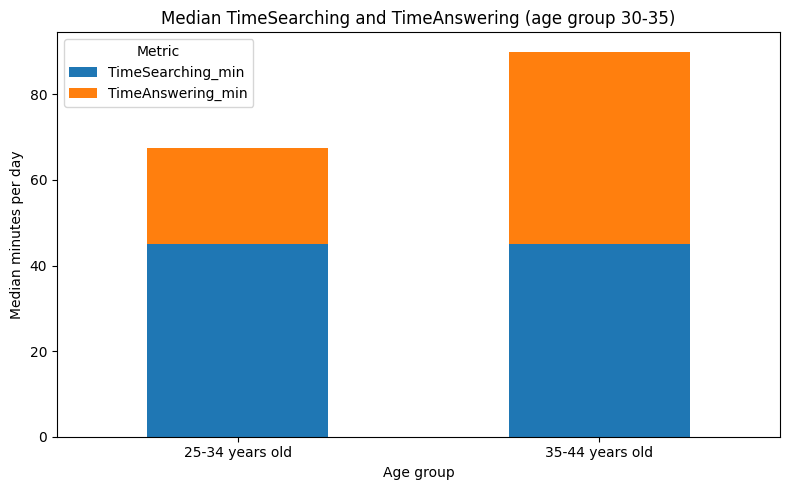

In [15]:
## Write your code here
# Stacked bar chart of median TimeSearching and TimeAnswering
# for the age group 30 to 35 (25-34 and 35-44 age buckets)
time_map = {
    'Less than 15 minutes a day': 7.5,
    '15-30 minutes a day': 22.5,
    '30-60 minutes a day': 45,
    '60-120 minutes a day': 90,
    'Over 120 minutes a day': 150,
}
age_groups = ['25-34 years old', '35-44 years old']
subset = df[df['Age'].isin(age_groups)].copy()
subset['TimeSearching_min'] = subset['TimeSearching'].map(time_map)
subset['TimeAnswering_min'] = subset['TimeAnswering'].map(time_map)

medians = subset.groupby('Age')[['TimeSearching_min', 'TimeAnswering_min']].median()
print(medians)
medians.plot(kind='bar', stacked=True, figsize=(8, 5))
plt.title('Median TimeSearching and TimeAnswering (age group 30-35)')
plt.xlabel('Age group')
plt.ylabel('Median minutes per day')
plt.xticks(rotation=0)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

### Visualizing Comparison of Data

**Line Chart**

Plot the median `CompTotal` for all ages from 45 to 60.


Age
45-54 years old    130000.0
55-64 years old    135000.0
Name: CompTotal, dtype: float64


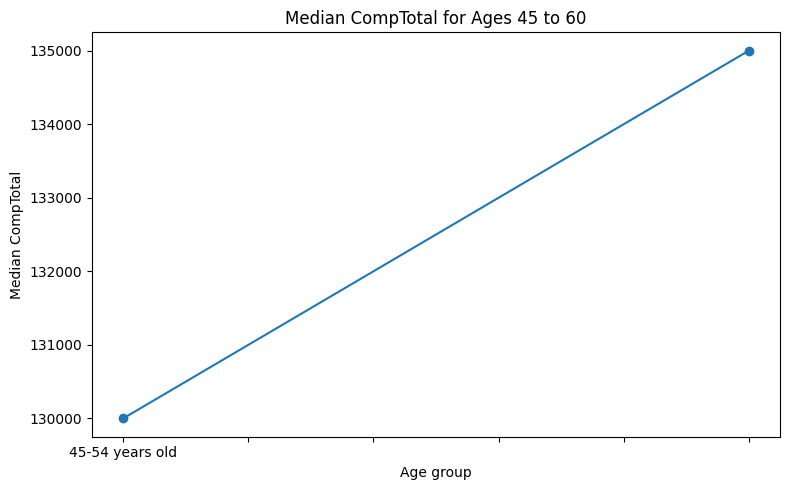

In [16]:
## Write your code here
# Line chart of median CompTotal for ages 45 to 60
age_groups = ['45-54 years old', '55-64 years old']
subset = df[df['Age'].isin(age_groups)]
median_comp = subset.groupby('Age')['CompTotal'].median()
print(median_comp)
plt.figure(figsize=(8, 5))
median_comp.plot(kind='line', marker='o')
plt.title('Median CompTotal for Ages 45 to 60')
plt.xlabel('Age group')
plt.ylabel('Median CompTotal')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Bar Chart**

Create a horizontal bar chart using the `MainBranch` column.


MainBranch
I am a developer by profession                                                           50207
I am not primarily a developer, but I write code sometimes as part of my work/studies     6511
I am learning to code                                                                     3875
I code primarily as a hobby                                                               3334
I used to be a developer by profession, but no longer am                                  1510
Name: count, dtype: int64


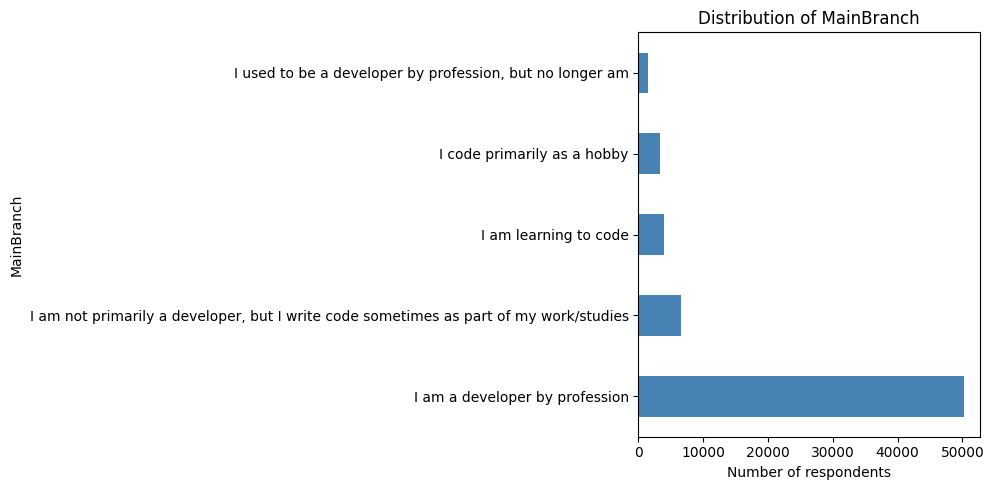

In [17]:
## Write your code here
# Horizontal bar chart of MainBranch
branch_counts = df['MainBranch'].value_counts()
print(branch_counts)
plt.figure(figsize=(10, 5))
branch_counts.plot(kind='barh', color='steelblue')
plt.title('Distribution of MainBranch')
plt.xlabel('Number of respondents')
plt.ylabel('MainBranch')
plt.tight_layout()
plt.show()

### Summary


In this lab, you focused on extracting and visualizing data from an RDBMS using SQL queries and SQLite. You applied various visualization techniques, including:

- Histograms to display the distribution of CompTotal.
- Box plots to show the spread of ages.
- Scatter plots and bubble plots to explore relationships between variables like Age, WorkExp, `TimeSearching` and `TimeAnswering`.
- Pie charts and stacked charts to visualize the composition of data.
- Line charts and bar charts to compare data across categories.


### Close the Database Connection

Once the lab is complete, ensure to close the database connection:


In [18]:
conn.close()

## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
